In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns    # to plot data 
from matplotlib.ticker import FuncFormatter

In [ ]:
# Load the CSV files from the project's data directory.
df=pd.read_csv('C:/Users/Ghafran/Downloads/SQL/python_learning/Itlay_Covid_Project/covid19_italy_province.csv')
df2=pd.read_csv('C:/Users/Ghafran/Downloads/SQL/python_learning/Itlay_Covid_Project/covid19_italy_region.csv')
# Preview the province-level data.
df.head(5)
df.shape

(40201, 11)

In [4]:
df2.shape

(6027, 17)

In [5]:
df_final2=df.merge(df2)
df_final2.shape

(1, 20)

In [6]:
df_final2.head()

,SNo,Date,Country,RegionCode,RegionName,ProvinceCode,ProvinceName,ProvinceAbbreviation,Latitude,Longitude,TotalPositiveCases,HospitalizedPatients,IntensiveCarePatients,TotalHospitalizedPatients,HomeConfinement,CurrentPositiveCases,NewPositiveCases,Recovered,Deaths,TestsPerformed
0,0,2020-02-24T18:00:00,ITA,13,Abruzzo,66,L'Aquila,AQ,42.351222,13.398438,0,0,0,0,0,0,0,0,0,NaN


In [7]:
df.shape


(40201, 11)

In [8]:
print(df.iloc[40199])  # integer location in pandas

SNo                                                  40199
Date                                   2020-12-06T17:00:00
Country                                                ITA
RegionCode                                               5
RegionName                                          Veneto
ProvinceCode                                           899
ProvinceName            Fuori Regione / Provincia Autonoma
ProvinceAbbreviation                                   NaN
Latitude                                               NaN
Longitude                                              NaN
TotalPositiveCases                                    2809
Name: 40199, dtype: object


In [9]:
df.columns

Index(['SNo', 'Date', 'Country', 'RegionCode', 'RegionName', 'ProvinceCode',
       'ProvinceName', 'ProvinceAbbreviation', 'Latitude', 'Longitude',
       'TotalPositiveCases'],
      dtype='object')

In [10]:
df.info()
#Non-Null Count -> Number of non-empty value in each column

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40201 entries, 0 to 40200
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   SNo                   40201 non-null  int64  
 1   Date                  40201 non-null  object 
 2   Country               40201 non-null  object 
 3   RegionCode            40201 non-null  int64  
 4   RegionName            40201 non-null  object 
 5   ProvinceCode          40201 non-null  int64  
 6   ProvinceName          40201 non-null  object 
 7   ProvinceAbbreviation  30422 non-null  object 
 8   Latitude              30709 non-null  float64
 9   Longitude             30709 non-null  float64
 10  TotalPositiveCases    40201 non-null  int64  
dtypes: float64(2), int64(4), object(5)
memory usage: 3.4+ MB


In [ ]:
# Review column data types and non-null counts.
is_infinite=df.isnull().sum()/df.shape[0]*100
print(is_infinite)

SNo                      0.000000
Date                     0.000000
Country                  0.000000
RegionCode               0.000000
RegionName               0.000000
ProvinceCode             0.000000
ProvinceName             0.000000
ProvinceAbbreviation    24.325266
Latitude                23.611353
Longitude               23.611353
TotalPositiveCases       0.000000
dtype: float64


In [12]:
df.describe()  # Returns the statistical description of dataframe

,SNo,RegionCode,ProvinceCode,Latitude,Longitude,TotalPositiveCases
count,40201.000000,40201.000000,40201.000000,30709.000000,30709.000000,40201.000000
mean,20100.000000,10.357354,266.261188,42.908522,12.096599,2563.579961
std,11605.173423,5.993795,383.221679,2.631552,2.660590,6884.484083
min,0.000000,1.000000,1.000000,36.925092,7.320149,0.000000
25%,10050.000000,5.000000,36.000000,40.914047,9.828190,103.000000
50%,20100.000000,9.000000,71.000000,43.715532,12.104734,642.000000
75%,30150.000000,16.000000,110.000000,45.185093,14.167546,2605.000000
max,40200.000000,22.000000,999.000000,46.499335,18.171897,158717.000000


In [13]:
df.head(2)

,SNo,Date,Country,RegionCode,RegionName,ProvinceCode,ProvinceName,ProvinceAbbreviation,Latitude,Longitude,TotalPositiveCases
0,0,2020-02-24T18:00:00,ITA,13,Abruzzo,66,L'Aquila,AQ,42.351222,13.398438,0
1,1,2020-02-24T18:00:00,ITA,13,Abruzzo,67,Teramo,TE,42.658918,13.704400,0


In [14]:
df2.head(2)

,SNo,Date,Country,RegionCode,RegionName,Latitude,Longitude,HospitalizedPatients,IntensiveCarePatients,TotalHospitalizedPatients,HomeConfinement,CurrentPositiveCases,NewPositiveCases,Recovered,Deaths,TotalPositiveCases,TestsPerformed
0,0,2020-02-24T18:00:00,ITA,13,Abruzzo,42.351222,13.398438,0,0,0,0,0,0,0,0,0,NaN
1,1,2020-02-24T18:00:00,ITA,17,Basilicata,40.639471,15.805148,0,0,0,0,0,0,0,0,0,NaN


In [15]:

df_final=df.merge(df2, on='SNo')
display(df_final.head(2))

,SNo,Date_x,Country_x,RegionCode_x,RegionName_x,ProvinceCode,ProvinceName,ProvinceAbbreviation,Latitude_x,Longitude_x,...,HospitalizedPatients,IntensiveCarePatients,TotalHospitalizedPatients,HomeConfinement,CurrentPositiveCases,NewPositiveCases,Recovered,Deaths,TotalPositiveCases_y,TestsPerformed
0,0,2020-02-24T18:00:00,ITA,13,Abruzzo,66,L'Aquila,AQ,42.351222,13.398438,...,0,0,0,0,0,0,0,0,0,NaN
1,1,2020-02-24T18:00:00,ITA,13,Abruzzo,67,Teramo,TE,42.658918,13.704400,...,0,0,0,0,0,0,0,0,0,NaN


In [ ]:
# Percentage of missing values for each column.
df_final.isnull().sum()/df_final.shape[0]*100

SNo                           0.000000
Date_x                        0.000000
Country_x                     0.000000
RegionCode_x                  0.000000
RegionName_x                  0.000000
ProvinceCode                  0.000000
ProvinceName                  0.000000
ProvinceAbbreviation         17.189315
Latitude_x                   16.409491
Longitude_x                  16.409491
TotalPositiveCases_x          0.000000
Date_y                        0.000000
Country_y                     0.000000
RegionCode_y                  0.000000
RegionName_y                  0.000000
Latitude_y                    0.000000
Longitude_y                   0.000000
HospitalizedPatients          0.000000
IntensiveCarePatients         0.000000
TotalHospitalizedPatients     0.000000
HomeConfinement               0.000000
CurrentPositiveCases          0.000000
NewPositiveCases              0.000000
Recovered                     0.000000
Deaths                        0.000000
TotalPositiveCases_y     

In [17]:
df_final.describe()   #  give the summary of CSV file

,SNo,RegionCode_x,ProvinceCode,Latitude_x,Longitude_x,TotalPositiveCases_x,RegionCode_y,Latitude_y,Longitude_y,HospitalizedPatients,IntensiveCarePatients,TotalHospitalizedPatients,HomeConfinement,CurrentPositiveCases,NewPositiveCases,Recovered,Deaths,TotalPositiveCases_y,TestsPerformed
count,6027.000000,6027.000000,6027.000000,5038.000000,5038.000000,6027.000000,6027.000000,6027.000000,6027.000000,6027.000000,6027.000000,6027.000000,6027.000000,6027.000000,6027.000000,6027.000000,6027.000000,6027.00000,4.872000e+03
mean,3013.000000,10.696200,207.579227,42.904803,12.102059,417.165256,11.857143,43.046293,12.225955,509.093579,55.892318,564.985897,5722.911399,6287.897296,286.885847,9337.852829,1474.370665,17100.12361,2.600810e+05
std,1739.989368,6.126295,347.418245,2.631800,2.662053,1084.140183,6.274319,2.488987,2.659168,1272.731157,134.957979,1403.362341,15892.768789,16804.884786,818.450458,20551.265039,3365.190225,36934.67627,3.339818e+05
min,0.000000,1.000000,1.000000,36.925092,7.320149,0.000000,1.000000,38.115697,7.320149,0.000000,0.000000,0.000000,0.000000,0.000000,-229.000000,0.000000,0.000000,0.00000,3.482000e+03
25%,1506.500000,6.000000,33.000000,40.914047,9.828190,1.000000,7.000000,41.125596,11.121231,16.000000,1.000000,17.000000,139.000000,168.000000,4.000000,734.000000,98.000000,1383.50000,6.507375e+04
50%,3013.000000,10.000000,65.000000,43.715532,12.104734,54.000000,12.000000,43.616760,12.388247,93.000000,9.000000,106.000000,743.000000,905.000000,31.000000,2840.000000,389.000000,4613.00000,1.365560e+05
75%,4519.500000,16.000000,96.000000,45.185093,14.167546,334.000000,17.000000,45.434905,13.768136,384.500000,46.000000,434.000000,3057.000000,3735.000000,159.500000,8450.500000,1102.500000,15304.00000,3.043542e+05
max,6026.000000,22.000000,999.000000,46.499335,18.171897,12748.000000,22.000000,46.499335,16.867367,12077.000000,1381.000000,13328.000000,155066.000000,164406.000000,11489.000000,289706.000000,23024.000000,429109.00000,2.415099e+06


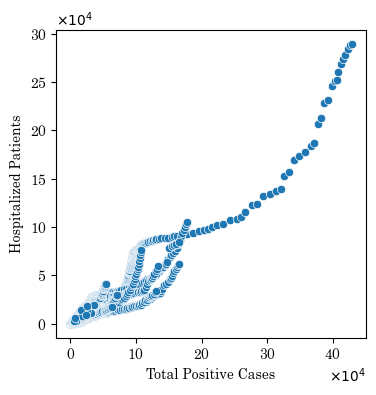

In [ ]:
# Plot total positive cases against recovered cases.
plt.figure(figsize=(4, 4))

#sns.set_style('white')

sns.scatterplot(
    data=df_final,
    x='TotalPositiveCases_y',
    y='Recovered'
     )
plt.xlabel('Total Positive Cases',fontname='Century',fontsize=10)
plt.ylabel('Hospitalized Patients',fontname='Century',fontsize=10)
plt.xticks(fontname='Century',fontsize=10)
plt.yticks(fontname='Century',fontsize=10)

plt.ticklabel_format(
    axis='both',
    style='sci',
    scilimits=(4, 4),
    useMathText=True
)

plt.box(True)
plt.show()

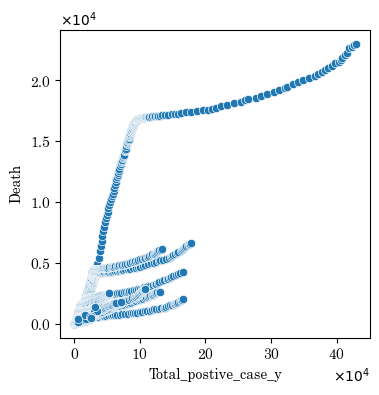

In [ ]:
# Plot total positive cases against deaths.
plt.figure(figsize=(4,4))
#sns.set_style('white')

sns.scatterplot(
    data=df_final,
    x='TotalPositiveCases_y',
    y='Deaths')

plt.xlabel('Total_postive_case_y',fontname='century',fontsize=10)
plt.ylabel('Death',fontname='century',fontsize=10)
plt.xticks(fontname='century',fontsize=10)
plt.yticks(fontname='century',fontsize=10)

plt.ticklabel_format(
    axis='both',
    style='sci',
    scilimits=(4, 4),
    useMathText=True
)

plt.box(True)
plt.show()

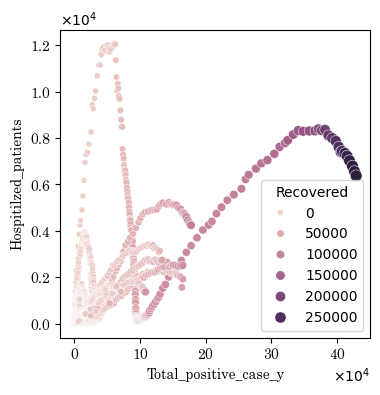

In [ ]:
# Plot total positive cases against hospitalized patients.
# Point size and colour represent the number of recovered cases.
plt.figure(figsize=(4,4))


sns.scatterplot(
    data=df_final,
    x='TotalPositiveCases_y',
    y='HospitalizedPatients',
    size='Recovered',
    hue='Recovered')

plt.xlabel("Total_positive_case_y",fontname='century',fontsize=10)
plt.ylabel('Hospitilzed_patients',fontname='century',fontsize=10)
plt.xticks(fontname='century',fontsize=10)
plt.yticks(fontname='century',fontsize=10)

plt.ticklabel_format(
    axis='both',
    style='sci',
    scilimits=(4,4),
    useMathText='True'
)

plt.box(True)
plt.show()

In [ ]:
# Count records for each region and sort the result by region name.
df_final["RegionName_x"].value_counts().sort_index()

RegionName_x
Abruzzo                  240
Basilicata               144
Calabria                 285
Campania                 282
Emilia-Romagna           470
Friuli Venezia Giulia    235
Lazio                    282
Liguria                  235
Lombardia                611
Marche                   282
Molise                   141
P.A. Bolzano              94
P.A. Trento               94
Piemonte                 423
Puglia                   329
Sardegna                 282
Sicilia                  470
Toscana                  517
Umbria                   141
Valle d'Aosta             94
Veneto                   376
Name: count, dtype: int64

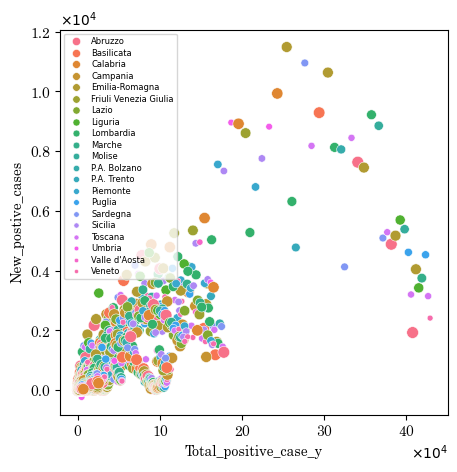

In [ ]:
# Compare new positive cases across regions.
plt.figure(figsize=(5,5))

sns.scatterplot(
    data=df_final,
    x='TotalPositiveCases_y',
    y='NewPositiveCases',
    hue='RegionName_x',
    size='RegionName_x'
)

plt.xlabel("Total_positive_case_y", fontname='century',  fontsize=10)
plt.ylabel("New_postive_cases", fontname='century',  fontsize=10)
plt.xticks(fontname='century',  fontsize=10)
plt.yticks(fontname='century',  fontsize=10)


plt.legend(
    fontsize=6,
    title_fontsize=7,
    markerscale=0.7,
    labelspacing=0.3,
    borderpad=0.4
)

plt.ticklabel_format(
    axis='both',
    style='sci',
    scilimits=(4,4),
    useMathText='True'
)

plt.box(True)
plt.show()
